## **LAB  - 06**
## **Name - Shubhi Kumari**
## **Section - C_C3**
## **Roll No - 34**

**1. Aim**

To convert a trained TensorFlow model into TensorFlow Lite (TFLite) format and perform
inference using the optimized model for Edge AI applications.

Import Required Libraries

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

In [ ]:
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


Load the IMDB Dataset

In [ ]:
max_features = 10000
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=max_features)

print("Original training data shape:", x_train.shape) # (25000,)
print("First review sequence length:", len(x_train[0]))

Original training data shape: (25000,)
First review sequence length: 218


Normalize the Dataset

In [ ]:
maxlen = 200 # Standardize all reviews to 200 words
x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train, maxlen=maxlen)
x_test = tf.keras.preprocessing.sequence.pad_sequences(x_test, maxlen=maxlen)

print("Padded training data shape:", x_train.shape) # Now (25000, 200)

Padded training data shape: (25000, 200)


Display a Sample Image

TypeError: Invalid shape (200,) for image data

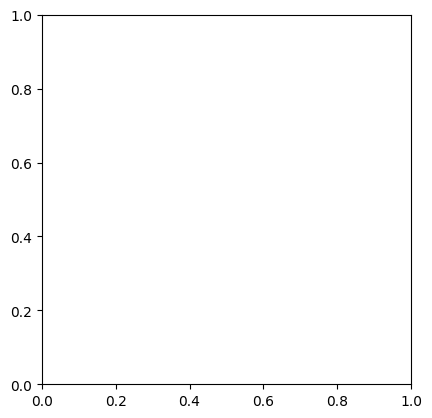

In [ ]:
plt.imshow(x_train[0], cmap="gray")
plt.title("Sample MNIST Image")
plt.axis("off")
plt.show()
print("Actual Label:", y_train[0])

Build the TensorFlow/Keras Model

In [ ]:
model = tf.keras.Sequential([
tf.keras.layers.Flatten(input_shape=(28, 28)),
tf.keras.layers.Dense(128, activation="relu"),
tf.keras.layers.Dense(10, activation="softmax")
])

Compile the Model

In [ ]:
model.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)

Display Model Architecture

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Train the Model

In [ ]:
history = model.fit(
x_train,
y_train,
epochs=5,
validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6968 - loss: 1.2238 - val_accuracy: 0.8720 - val_loss: 0.5780
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8651 - loss: 0.5201 - val_accuracy: 0.9080 - val_loss: 0.3740
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8907 - loss: 0.4020 - val_accuracy: 0.9138 - val_loss: 0.3101
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8997 - loss: 0.3551 - val_accuracy: 0.9233 - val_loss: 0.2783
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9063 - loss: 0.3294 - val_accuracy: 0.9267 - val_loss: 0.2642


Evaluate the Original TensorFlow
Model

In [ ]:
test_loss, test_accuracy = model.evaluate(
x_test,
y_test,
verbose=0
)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.913100004196167


Perform Prediction Using TensorFlow
Model

In [ ]:
sample = x_test[0:1]
prediction = model.predict(sample)
predicted_class = np.argmax(prediction)
print("Actual Label:", y_test[0])
print("Predicted Label:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Actual Label: 7
Predicted Label: 7


Convert TensorFlow Model to
TensorFlow Lite

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

In [ ]:
tflite_model = converter.convert()

Saved artifact at '/tmp/tmpml20lnih'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  137523253188880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137523253185232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137523253186576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137523253184848: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [ ]:
with open("mnist_model.tflite", "wb") as f:
  f.write(tflite_model)
print("TensorFlow Lite model saved successfully.")

TensorFlow Lite model saved successfully.


Check TFLite Model Size

In [ ]:
tflite_size = os.path.getsize("mnist_model.tflite")
print(
"TFLite Model Size:",
tflite_size / 1024,
"KB"
)

TFLite Model Size: 400.140625 KB


Load the TFLite Model

In [ ]:
interpreter = tf.lite.Interpreter(
model_path="mnist_model.tflite"
)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
interpreter.allocate_tensors()

Get Input and Output Details

In [ ]:
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("Input Details:")
print(input_details)
print("\nOutput Details:")
print(output_details)

Input Details:
[{'name': 'serving_default_keras_tensor_5:0', 'index': 0, 'shape': array([ 1, 28, 28], dtype=int32), 'shape_signature': array([-1, 28, 28], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]

Output Details:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 14, 'shape': array([ 1, 10], dtype=int32), 'shape_signature': array([-1, 10], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]


Prepare Input Data

In [ ]:
input_data = x_test[0:1]

In [ ]:
print("Input Shape:", input_data.shape)

Input Shape: (1, 28, 28)


Perform Inference Using TFLite

In [ ]:
interpreter.set_tensor(
input_details[0]["index"],
input_data
)

In [ ]:
interpreter.invoke()

In [ ]:
output_data = interpreter.get_tensor(
output_details[0]["index"]
)
predicted_class = np.argmax(output_data)
print("Actual Label:", y_test[0])
print("TFLite Predicted Label:", predicted_class)

Actual Label: 7
TFLite Predicted Label: 7


Compare TensorFlow and TFLite
Predictions

In [ ]:
tf_prediction = np.argmax(
model.predict(x_test[0:1])
)
tflite_prediction = np.argmax(
output_data
)
print("TensorFlow Prediction:", tf_prediction)
print("TFLite Prediction:", tflite_prediction)
print("Actual Label:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
TensorFlow Prediction: 7
TFLite Prediction: 7
Actual Label: 7


Test Multiple Samples

In [ ]:
correct = 0
total = 100
for i in range(total):
    input_data = x_test[i:i+1]
    interpreter.set_tensor(
        input_details[0]["index"],
        input_data
    )
    interpreter.invoke()
    output_data = interpreter.get_tensor(
        output_details[0]["index"]
    )
    prediction = np.argmax(output_data)
    if prediction == y_test[i]:
        correct += 1
accuracy = correct / total
print("TFLite Accuracy on", total, "samples:", accuracy)

TFLite Accuracy on 100 samples: 0.92


Quantize the Model

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [
tf.lite.Optimize.DEFAULT
]
quantized_tflite_model = converter.convert()
with open("mnist_model_quantized.tflite", "wb") as f:
  f.write(quantized_tflite_model)
print("Quantized TFLite model saved.")

Saved artifact at '/tmp/tmpoglr1b6n'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  137523253188880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137523253185232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137523253186576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137523253184848: TensorSpec(shape=(), dtype=tf.resource, name=None)
Quantized TFLite model saved.


Compare Model Sizes

In [ ]:
original_size = os.path.getsize("mnist_model.tflite")
quantized_size = os.path.getsize(
"mnist_model_quantized.tflite"
)
print(
"Original TFLite Model:",
original_size / 1024,
"KB"
)
print(
"Quantized TFLite Model:",
quantized_size / 1024,
"KB"
)

Original TFLite Model: 400.140625 KB
Quantized TFLite Model: 104.1171875 KB
